# Toronto collision patterns over time
## Person 1: independent temporal analysis (A1-A4)

**Question:** When were Toronto Police collision records most frequent in 2024 and 2025?

This report compares complete calendar years by month and pools both years for hour-of-day and weekday counts. It uses the original local CSV and only Person 1's modules. Results measure recorded frequency, not per-driver risk or collision causes.

Run **Restart Kernel and Run All** to reproduce every table, finding and chart.

## 1. Source and scope

Source: [Toronto Police Service Motor Vehicle Collisions](https://data.torontopolice.on.ca/datasets/bc4c72a793014a55a674984ef175a6f3_0/explore).

The supplied file is `Traffic Collisions - 4326 (1).csv`, a full historical export with 825,265 rows. The analysis selects 2024 and 2025. The supplied tickets expect 70,181 records in 2024 and 67,546 in 2025; these are checks against this particular file, not values used to construct the summaries.

The four required fields are `OCC_YEAR`, `OCC_MONTH`, `OCC_DOW` and `OCC_HOUR`. We use the recorded calendar fields directly. Although `OCC_DATE` in this export is stored in Unix milliseconds, we do not use its timestamp hour as the occurrence hour.

Unknown locations and zero-coordinate records remain included because the question is temporal. The original CSV is never written back to disk.

In [1]:
from pathlib import Path
import sys
# import pandas as pd 
# Find our folder whether Jupyter starts here or in the project folder.
PERSON_DIR = Path.cwd()
if not (PERSON_DIR / "ticket_1_prepare_data.py").is_file():
    PERSON_DIR = Path.cwd() / "person_1"
if not (PERSON_DIR / "ticket_1_prepare_data.py").is_file():
    PERSON_DIR = Path.cwd() / "Toronto_Winter_Road_Safety" / "person_1"
if not (PERSON_DIR / "ticket_1_prepare_data.py").is_file():
    raise FileNotFoundError("Open this notebook from person_1 or its project root.")

sys.path.insert(0, str(PERSON_DIR.resolve()))

import pandas as pd
from IPython.display import Image, Markdown, display
from ticket_1_prepare_data import (
    DEFAULT_CSV, REFERENCE_COUNTS, load_temporal_data, print_inspection,
)
from ticket_2_analyze_patterns import (
    collisions_by_month, collisions_by_hour, collisions_by_weekday,
    key_findings, verify_group_totals,
)
from ticket_3_create_charts import save_temporal_charts

CSV_PATH = DEFAULT_CSV  # Change this if your original CSV is somewhere else.
pd.options.display.max_rows = 30

## 2. Inspect and prepare the temporal subset (A1)

The loader selects 2024-2025, orders calendar labels, and checks for missing or invalid values. A valid hour is an integer from 0 to 23. Invalid month/day labels or hours become missing **in memory**, and the inspection reports them. No complete row is silently discarded just because one time field is missing.

In [2]:
# A1: read, select the two years, and check the four time columns.
df = load_temporal_data(CSV_PATH)
print_inspection(df)
display(df.head())

inspection = df.attrs["inspection"]
yearly = df["OCC_YEAR"].value_counts().sort_index()
display(yearly.rename("collision_records"))

# Verify the supplied source snapshot before continuing to the charts.
if inspection["rows_by_year"] != REFERENCE_COUNTS:
    raise ValueError("Row counts differ from the project snapshot. Check the CSV.")

Source: C:\Users\User\Downloads\better_ways\Toronto_Winter_Road_Safety\data\raw\collisions\Traffic Collisions - 4326 (1).csv
Source records: 825,265
Selected 2024-2025 records: 137,727
  2024: 70,181
  2025: 67,546
  Missing/invalid OCC_MONTH: 0
  Missing/invalid OCC_HOUR: 0
  Missing/invalid OCC_DOW: 0


,OCC_MONTH,OCC_DOW,OCC_YEAR,OCC_HOUR
0,January,Monday,2024,6
1,January,Monday,2024,18
2,January,Monday,2024,11
3,January,Monday,2024,18
4,January,Monday,2024,14


OCC_YEAR
2024    70181
2025    67546
Name: collision_records, dtype: int64

## 3. Summaries and reconciliation (A2)

Monthly totals use one row per year/month, ordered January-December. Hourly counts run from 00 to 23. Weekdays run Monday-Sunday. Hour and weekday totals combine both years.

Each grouping excludes only records missing that particular grouping field. Its total must equal the number of eligible records. The reconciliation makes any exclusions visible before visualization.

In [3]:
# A2: build three count tables using our analysis functions.
monthly = collisions_by_month(df)
hourly = collisions_by_hour(df)
weekday = collisions_by_weekday(df)

# Check that each summary includes every record eligible for that grouping.
checks = verify_group_totals(df)
display(checks)
display(monthly)
display(hourly)
display(weekday)

,grouping,eligible_records,excluded_records,grouped_total
0,Month,137727,0,137727
1,Hour,137727,0,137727
2,Weekday,137727,0,137727


,OCC_YEAR,OCC_MONTH,collisions
0,2024,January,5724
1,2024,February,5267
2,2024,March,5665
3,2024,April,5306
4,2024,May,6139
5,2024,June,6173
6,2024,July,5835
7,2024,August,5626
8,2024,September,6186
9,2024,October,6098


,OCC_HOUR,collisions
0,0,1651
1,1,1506
2,2,1319
3,3,1232
4,4,997
5,5,1282
6,6,2597
7,7,3960
8,8,7335
9,9,6968


,OCC_DOW,collisions
0,Monday,18390
1,Tuesday,21691
2,Wednesday,21010
3,Thursday,21739
4,Friday,21976
5,Saturday,18363
6,Sunday,14558


## 4. Monthly comparison (A3)

The two curves show raw collision-record counts for each month, separately for 2024 and 2025. Use them to describe differences in recorded frequency. Month lengths differ, so these are not daily rates. Seasonal appearance alone does not establish a weather effect.

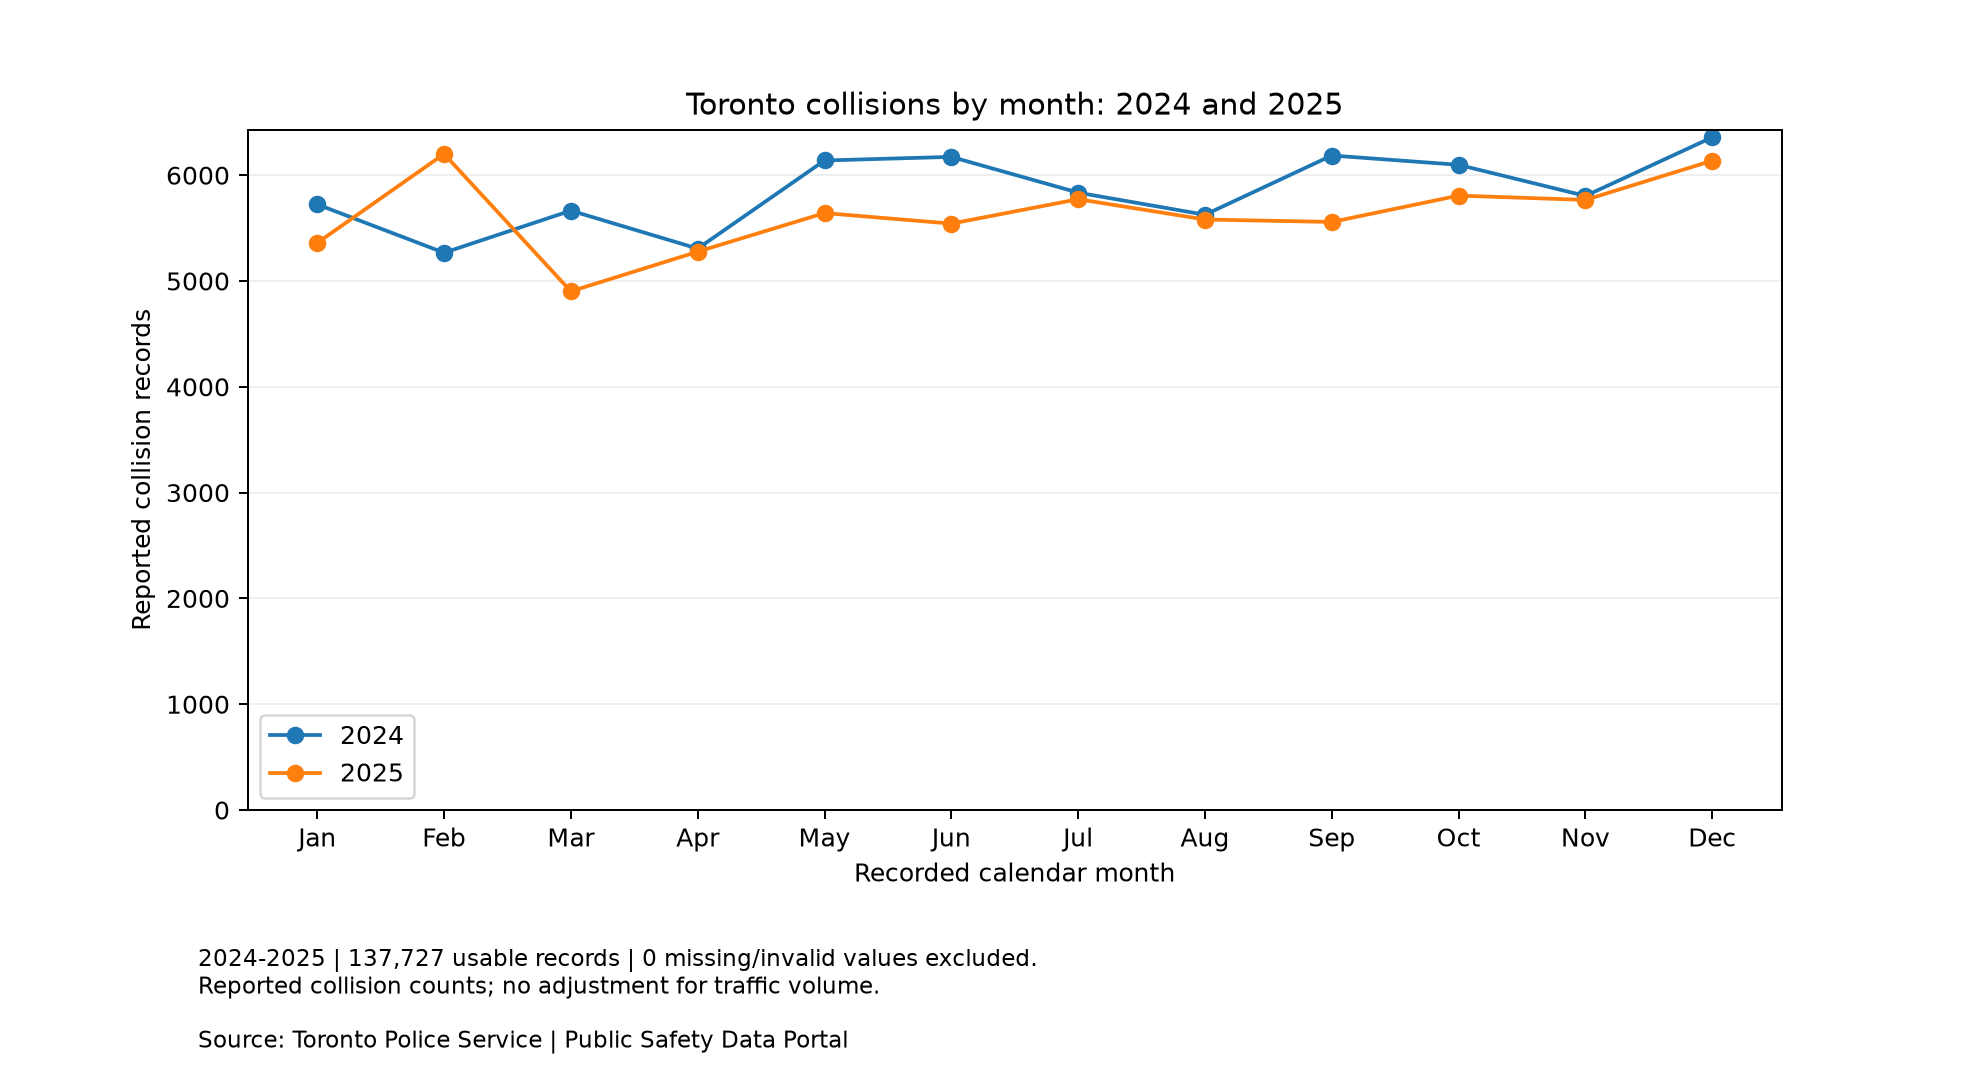

**Observation:** Highest-count year/month: December 2024, with 6,358 records each.

In [4]:
# A3: save all three charts, then display the monthly comparison.
figures = save_temporal_charts(df, PERSON_DIR / "figures")
display(Image(filename=str(figures["monthly"])))
display(Markdown("**Observation:** " + key_findings(df)[1]))

## 5. Hour-of-day pattern (A3)

Each bar combines the same recorded occurrence hour across every day in the two years. It is not a continuous 24-hour timeline. Higher counts may reflect more traffic and other unmeasured factors.

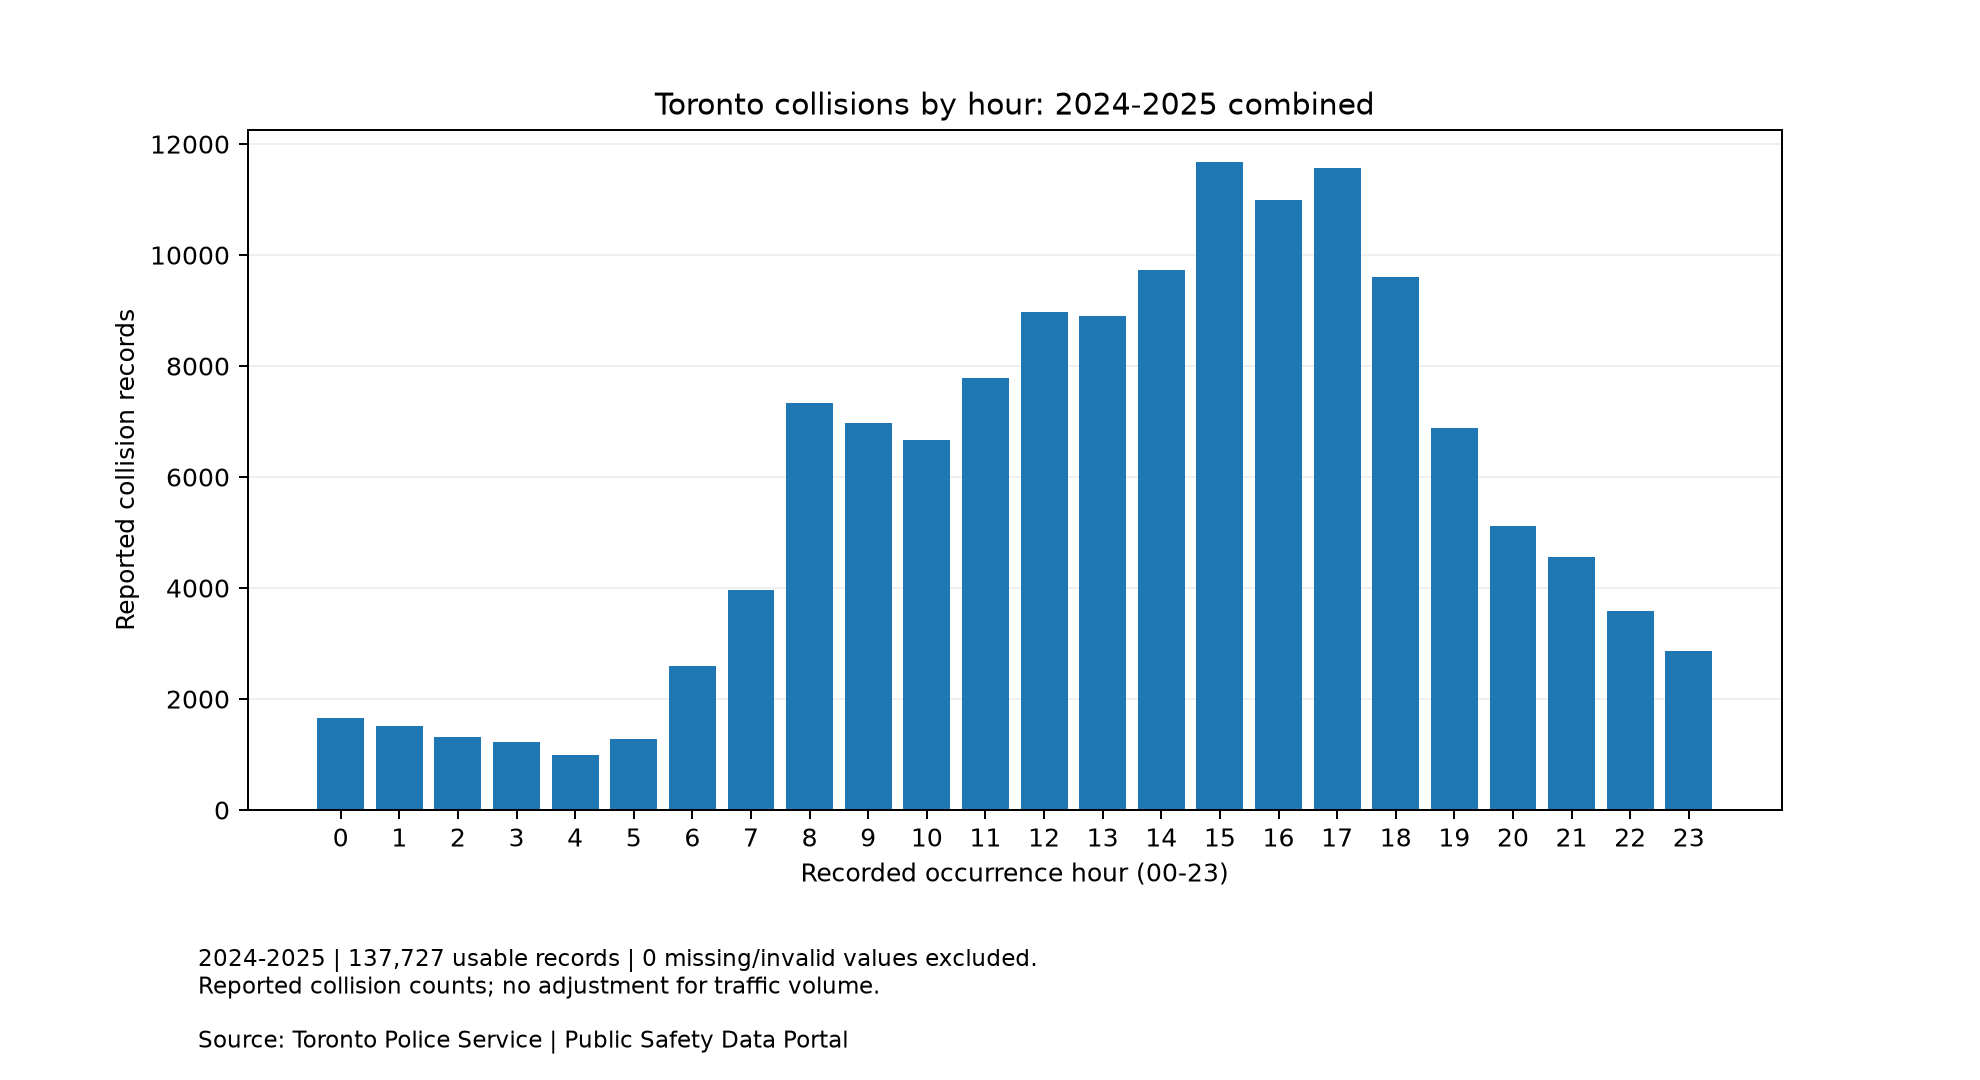

**Observation:** Highest-count hour: 15:00-15:59, with 11,677 records each across 2024-2025.

In [5]:
display(Image(filename=str(figures["hourly"])))
display(Markdown("**Observation:** " + key_findings(df)[2]))

## 6. Weekday pattern (A3)

The bars are calendar-ordered counts pooled over both years. They are not normalized by the number of Mondays, Tuesdays, etc. in the period, or by the number of people travelling.

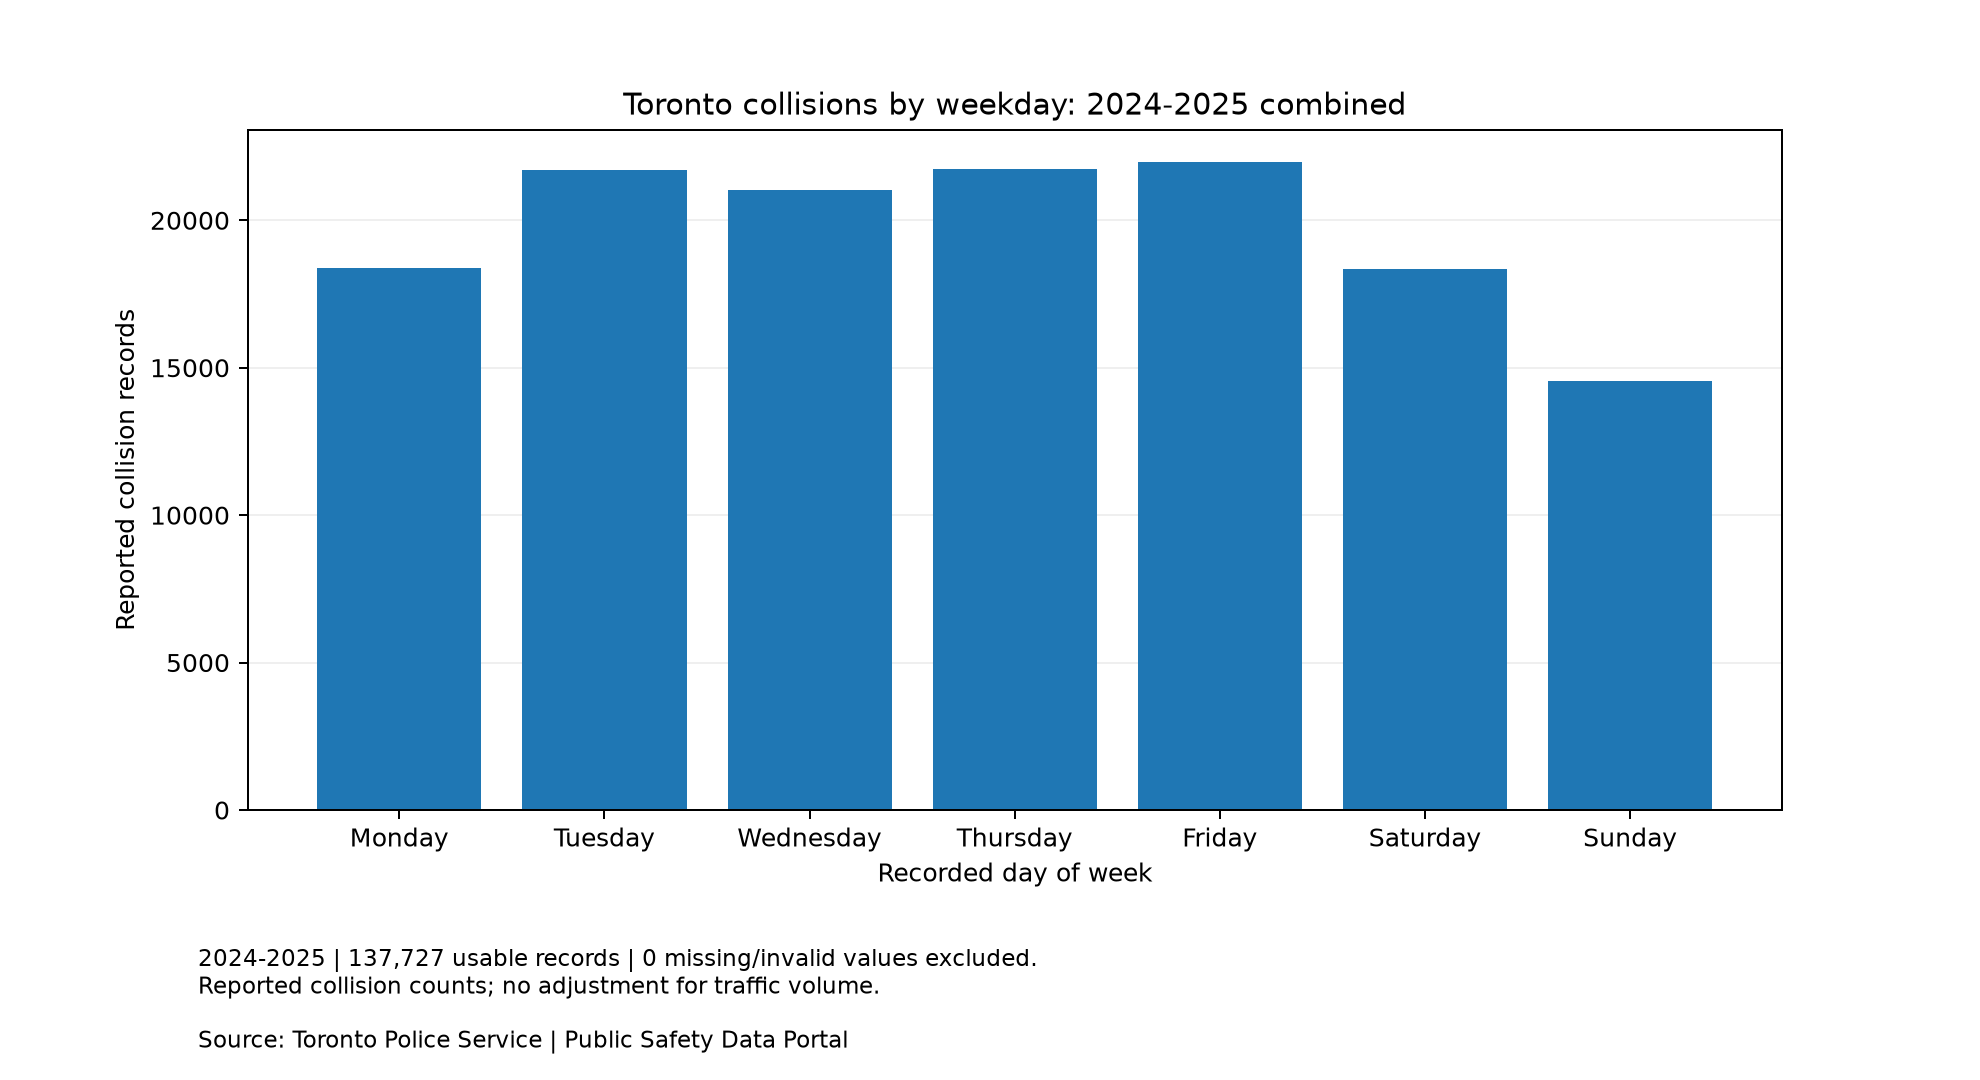

**Observation:** Highest-count weekday: Friday, with 21,976 records each across 2024-2025.

In [6]:
display(Image(filename=str(figures["weekday"])))
display(Markdown("**Observation:** " + key_findings(df)[3]))

## 7. Findings supported by the computed tables (A4)

The following text is calculated from the loaded CSV. It updates when the notebook is rerun with a compatible source snapshot.

In [7]:
# A4: display findings calculated from the summary tables.
for finding in key_findings(df):
    display(Markdown("- " + finding))

print(f"Selected records: {len(df):,}")
for column, missing in inspection["missing_or_invalid"].items():
    print(f"Missing or invalid {column}: {missing:,}")
print("Each summary reconciles to its eligible record count.")

- Reported records changed from 70,181 in 2024 to 67,546 in 2025 (-2,635; -3.75%).

- Highest-count year/month: December 2024, with 6,358 records each.

- Highest-count hour: 15:00-15:59, with 11,677 records each across 2024-2025.

- Highest-count weekday: Friday, with 21,976 records each across 2024-2025.

Selected records: 137,727
Missing or invalid OCC_MONTH: 0
Missing or invalid OCC_HOUR: 0
Missing or invalid OCC_DOW: 0
Each summary reconciles to its eligible record count.


## 8. Limitations and interpretation

- These are publisher-provided collision records. This four-column workstream does not independently deduplicate events.
- Traffic volume, distance travelled and road-user exposure are absent. High counts do not prove a higher probability of collision for an individual road user.
- The file has no snowfall or proven crash-cause field. No weather integration or causal claim is made.
- Counts use recorded calendar labels. We have not independently reconstructed the event time zone from other fields.
- Location quality is not a filter here. Unknown/NSA locations remain in the temporal totals; these records have not been geographically revalidated.
- Months vary in length and 2024 has 366 days. Weekday counts are not normalized for the number of occurrences of each weekday. The charts show raw frequencies.
- Data revisions, reporting practices and missing records can influence comparisons. Findings apply to this source snapshot and the specified two years.

**Practical use:** These patterns identify time periods that warrant further investigation. Additional exposure and contextual data would be needed for risk estimates or safety interventions.

## 9. Reproduce and explain the work

Run this notebook top to bottom in the environment described in `README.md`. The three PNGs are regenerated in `person_1/figures`. No Person 2 modules, outputs or notebook state are required.

Before presenting, be ready to explain the year filter, categorical ordering, grouping totals, per-group missing-data handling, and why counts do not establish causes or individual risk.